<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/07_Recommendation_Systems/notebooks/02_Collaborative_Filtering_User_and_Item_Based.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Collaborative Filtering: User-Based and Item-Based

## Objectives
- Understand user-based collaborative filtering.
- Understand item-based collaborative filtering.
- Calculate cosine similarity.
- Calculate Pearson correlation.
- Predict missing ratings.
- Generate Top-N recommendations.
- Evaluate recommendation quality.

## Dataset
Sample movie rating dataset

## Libraries
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib

In [4]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

In [5]:
#Create a user-item rating matrix
ratings = pd.DataFrame({
    "Avengers": [5, 5, 1, 2, 4],
    "Iron Man": [5, 4, 1, 1, 5],
    "Titanic": [1, 1, 5, 5, 2],
    "Interstellar": [4, 5, 2, 1, 5],
    "The Notebook": [1, 2, 5, 4, 1],
    "John Wick": [5, 4, 1, 2, 4]
}, index=[
    "User A",
    "User B",
    "User C",
    "User D",
    "User E"
])

display(ratings)

,Avengers,Iron Man,Titanic,Interstellar,The Notebook,John Wick
User A,5,5,1,4,1,5
User B,5,4,1,5,2,4
User C,1,1,5,2,5,1
User D,2,1,5,1,4,2
User E,4,5,2,5,1,4


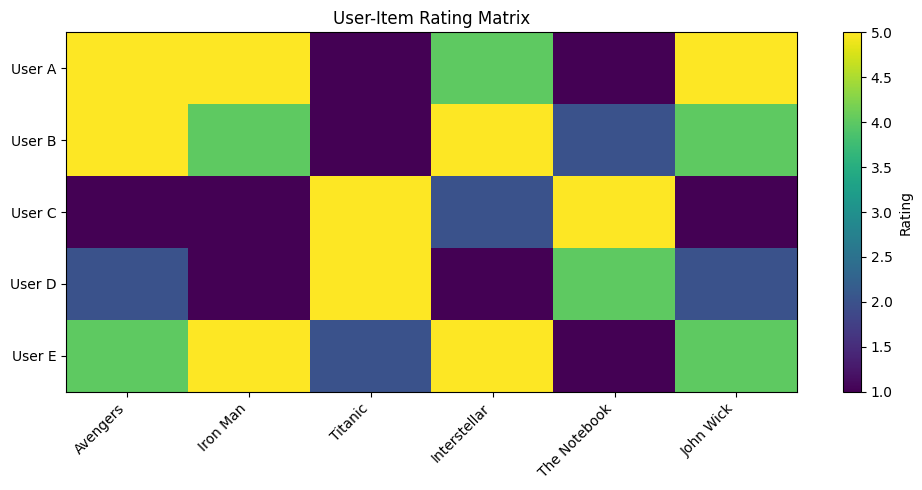

In [6]:
#Visualize the rating matrix
plt.figure(figsize=(10, 5))

plt.imshow(ratings, aspect="auto")

plt.xticks(
    range(len(ratings.columns)),
    ratings.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(ratings.index)),
    ratings.index
)

plt.colorbar(label="Rating")
plt.title("User-Item Rating Matrix")
plt.tight_layout()
plt.show()

In [7]:
#User-Based Collaborative Filtering
user_similarity = cosine_similarity(ratings)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=ratings.index,
    columns=ratings.index
)

display(user_similarity_df.round(3))

,User A,User B,User C,User D,User E
User A,1.000,0.978,0.453,0.552,0.978
User B,0.978,1.000,0.540,0.601,0.977
User C,0.453,0.540,1.000,0.964,0.540
User D,0.552,0.601,0.964,1.000,0.601
User E,0.978,0.977,0.540,0.601,1.000


In [8]:
#Find similar users
selected_user = "User A"

similar_users = user_similarity_df[
    selected_user
].drop(selected_user)

similar_users = similar_users.sort_values(
    ascending=False
)

print("Users most similar to", selected_user)

display(similar_users)

Users most similar to User A


,User A
User B,0.978321
User E,0.978321
User D,0.551769
User C,0.453247


In [9]:
#Create a missing rating
ratings_missing = ratings.copy()

ratings_missing.loc["User A", "Titanic"] = np.nan

display(ratings_missing)

,Avengers,Iron Man,Titanic,Interstellar,The Notebook,John Wick
User A,5,5,NaN,4,1,5
User B,5,4,1.0,5,2,4
User C,1,1,5.0,2,5,1
User D,2,1,5.0,1,4,2
User E,4,5,2.0,5,1,4


In [10]:
#Calculate user similarity using available ratings
def user_similarity_pair(user1, user2, rating_matrix):

    common_movies = rating_matrix.loc[
        [user1, user2]
    ].dropna(axis=1, how="any")

    if common_movies.shape[1] == 0:
        return 0

    vectors = common_movies.to_numpy()

    return cosine_similarity(
        vectors[0].reshape(1, -1),
        vectors[1].reshape(1, -1)
    )[0, 0]

In [11]:
#Predict User A's Titanic rating
def predict_user_rating(user, movie, rating_matrix):

    similarities = {}

    for other_user in rating_matrix.index:

        if other_user == user:
            continue

        if pd.notna(rating_matrix.loc[other_user, movie]):

            similarity = user_similarity_pair(
                user,
                other_user,
                rating_matrix
            )

            similarities[other_user] = similarity

    numerator = 0
    denominator = 0

    for other_user, similarity in similarities.items():

        rating = rating_matrix.loc[other_user, movie]

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return np.nan

    return numerator / denominator


predicted_rating = predict_user_rating(
    "User A",
    "Titanic",
    ratings_missing
)

print("Predicted Titanic rating for User A:", predicted_rating)

Predicted Titanic rating for User A: 2.822785040983356


In [12]:
#Calculate item similarity
item_similarity = cosine_similarity(
    ratings.T
)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=ratings.columns,
    columns=ratings.columns
)

display(item_similarity_df.round(3))

,Avengers,Iron Man,Titanic,Interstellar,The Notebook,John Wick
Avengers,1.000,0.979,0.523,0.972,0.554,0.995
Iron Man,0.979,1.000,0.470,0.979,0.478,0.986
Titanic,0.523,0.470,1.000,0.539,0.975,0.543
Interstellar,0.972,0.979,0.539,1.000,0.571,0.965
The Notebook,0.554,0.478,0.975,0.571,1.000,0.556
John Wick,0.995,0.986,0.543,0.965,0.556,1.000


In [13]:
#Find similar movies
selected_movie = "Avengers"

similar_movies = item_similarity_df[
    selected_movie
].drop(selected_movie)

similar_movies = similar_movies.sort_values(
    ascending=False
)

print("Movies similar to", selected_movie)

display(similar_movies)

Movies similar to Avengers


,Avengers
John Wick,0.994761
Iron Man,0.978645
Interstellar,0.971831
The Notebook,0.553952
Titanic,0.523348


In [14]:
#Predict missing ratings using Item-Based Filtering
def predict_item_rating(user, movie, rating_matrix, similarity_matrix):

    rated_movies = rating_matrix.loc[user].dropna()

    numerator = 0
    denominator = 0

    for other_movie, rating in rated_movies.items():

        similarity = similarity_matrix.loc[
            movie, other_movie
        ]

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return np.nan

    return numerator / denominator

In [15]:
#Predict Titanic rating
item_prediction = predict_item_rating(
    "User A",
    "Titanic",
    ratings_missing,
    item_similarity_df
)

print("Item-based predicted rating:", item_prediction)

Item-based predicted rating: 3.545130750995642


In [16]:
#Generate Top-N recommendations
#We'll create a function that recommends movies a user has not rated.
#For this demonstration, we use item-based rating predictions.

def recommend_top_n(user, rating_matrix, similarity_matrix, n=3):

    recommendations = {}

    for movie in rating_matrix.columns:

        if pd.isna(rating_matrix.loc[user, movie]):

            predicted_rating = predict_item_rating(
                user,
                movie,
                rating_matrix,
                similarity_matrix
            )

            if pd.notna(predicted_rating):
                recommendations[movie] = predicted_rating

    recommendations = sorted(
        recommendations.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return recommendations[:n]

In [17]:
#Test the recommendation function
recommendations = recommend_top_n(
    "User A",
    ratings_missing,
    item_similarity_df,
    n=3
)

print("Top recommendations for User A:")

for movie, predicted_rating in recommendations:

    print(
        movie,
        "| Predicted rating:",
        round(predicted_rating, 2)
    )

Top recommendations for User A:
Titanic | Predicted rating: 3.55


In [18]:
#Calculate user Pearson correlation
user_pearson = ratings.T.corr(
    method="pearson"
)

display(user_pearson.round(3))

,User A,User B,User C,User D,User E
User A,1.000,0.894,-1.000,-0.894,0.894
User B,0.894,1.000,-0.894,-0.926,0.852
User C,-1.000,-0.894,1.000,0.894,-0.894
User D,-0.894,-0.926,0.894,1.000,-0.926
User E,0.894,0.852,-0.894,-0.926,1.000


In [19]:
#Calculate item Pearson correlation
item_pearson = ratings.corr(
    method="pearson"
)

display(item_pearson.round(3))

,Avengers,Iron Man,Titanic,Interstellar,The Notebook,John Wick
Avengers,1.000,0.913,-0.980,0.848,-0.924,0.972
Iron Man,0.913,1.000,-0.940,0.913,-0.980,0.950
Titanic,-0.980,-0.940,1.000,-0.913,0.913,-0.950
Interstellar,0.848,0.913,-0.913,1.000,-0.848,0.804
The Notebook,-0.924,-0.980,0.913,-0.848,1.000,-0.972
John Wick,0.972,0.950,-0.950,0.804,-0.972,1.000


In [20]:
#Evaluation of recommendation systems
#Simple MAE and RMSE example

from sklearn.metrics import mean_absolute_error, mean_squared_error

actual_ratings = np.array([5, 4, 2, 1, 5])

predicted_ratings = np.array([4.5, 4.2, 2.5, 1.5, 4.7])

mae = mean_absolute_error(
    actual_ratings,
    predicted_ratings
)

rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        predicted_ratings
    )
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.4
RMSE: 0.41952353926806063


## Conclusion

In this lesson, we implemented user-based and item-based
collaborative filtering.

Cosine similarity was used to identify similar users
and movies. Similarity-weighted methods were implemented
to predict missing ratings and generate Top-N recommendations.

Pearson correlation was also explored as an alternative
similarity measure.

Finally, MAE and RMSE were introduced for evaluating
rating prediction accuracy.

The experiment demonstrates how user interactions
can be used to build personalized recommendation systems.